# Лабораторная работа по математическому анализу
## Локальное приближение функций и численная производная

**ОП «Нейротехнологии и программирование» · 1 семестр**

---

### О чём эта работа

В течение семестра производная появляется сразу в нескольких ролях: как предел, как характеристика локального поведения функции и как инструмент исследования. На компьютере возникает ещё один вопрос: что делать, если производную нужно получить по значениям функции и насколько такому вычислению можно доверять?

Работа строится вокруг одной линии. Сначала функция локально заменяется полиномом Тейлора. Из того же разложения выводятся формулы численного дифференцирования. Затем исследуются их погрешность, ограничения машинной арифметики и роль гладкости функции. В конце численная производная используется для проверки аналитической формулы и для настройки одного параметра простой модели.


In [10]:
# Блок 0.1: импорты и настройки графиков
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True
pd.set_option("display.float_format", lambda v: f"{v:.3e}")

In [11]:
# Блок 0.2: загрузка JSON 
FILE = "lab1_math_variant_022.json"

DEFAULT = {
    "smooth_function": {"params": {"a": 1.640076125441082, "b": 2,
                                   "c": 0.23779684964111997, "d": -2.198180283363944},
                        "x0": 0.2975627580667383},
    "calibration": {"finite_difference_steps": {"large": 0.1, "too_small": 1e-17, "control": 0.00001}},
    "experiment": {"h_min": 1e-20, "h_max": 1, "n_h": 260},
    "nonsmooth_test": {"name": "x_abs_x", "x0": 0},
}

if not os.path.exists(FILE):
    try:
        from google.colab import files
        print("Выберите файл", FILE, "(или отмените - возьмём значения по умолчанию)")
        files.upload()
    except Exception:
        pass

if os.path.exists(FILE):
    with open(FILE, encoding="utf8") as fh:
        cfg = json.load(fh)
    print("Данные загружены из файла")
else:
    cfg = DEFAULT
    print("Файл не найден, используются значения по умолчанию")

a, b, c, d = (cfg["smooth_function"]["params"][k] for k in "abcd")
x0 = cfg["smooth_function"]["x0"]
steps = cfg["calibration"]["finite_difference_steps"]
exp = cfg["experiment"]
print(f"f(x) = {a:.4f}*sin({b}x) + {c:.4f}*x^2 + ({d:.4f})*x,  x0 = {x0:.6f}")

Файл не найден, используются значения по умолчанию
f(x) = 1.6401*sin(2x) + 0.2378*x^2 + (-2.1982)*x,  x0 = 0.297563


In [12]:
# Блок 0.3: функция f и её производные (аналитически, для сравнения)
def f(x, xp=np):
    """f(x) = a sin(bx) + c x^2 + d x. xp - модуль (np), чтобы работать и с float32."""
    return a * xp.sin(b * x) + c * x**2 + d * x

def df(x):   return a * b * np.cos(b * x) + 2 * c * x + d       # первая производная
def d2f(x):  return -a * b**2 * np.sin(b * x) + 2 * c            # вторая производная
def d3f(x):  return -a * b**3 * np.cos(b * x)                    # третья производная

exact = df(x0)  # "истинное" значение f'(x0)
print("f'(x0) точно =", exact)

f'(x0) точно = 0.6595610624538222


## 1. Полиномы Тейлора и локальная ошибка

### 1.1. Аналитический вывод производных и полиномов

По условию индивидуального варианта функция имеет вид

$$
f(x)=a\sin(bx)+cx^2+dx,
$$

где $a=1{,}640076125441082$, $b=2$, $c=0{,}23779684964111997$, $d=-2{,}198180283363944$ и $x_0=0{,}2975627580667383$.

Применяя формулы $(\sin bx)'=b\cos bx$, $(\cos bx)'=-b\sin bx$ и $(x^2)'=2x$, получаем

$$
\begin{aligned}
f'(x)&=ab\cos(bx)+2cx+d,\\
f''(x)&=-ab^2\sin(bx)+2c,\\
f'''(x)&=-ab^3\cos(bx).
\end{aligned}
$$

После подстановки коэффициентов:

$$
\begin{aligned}
f'(x)&=3{,}280152250882164\cos(2x)+0{,}475593699282240x-2{,}198180283363944,\\
f''(x)&=-6{,}560304501764328\sin(2x)+0{,}475593699282240,\\
f'''(x)&=-13{,}120609003528656\cos(2x).
\end{aligned}
$$

В точке $x_0$ получаем

$$
\begin{aligned}
f(x_0)&\approx0{,}286406298560,\\
f'(x_0)&\approx0{,}659561062454,\\
f''(x_0)&\approx-3{,}202196294563,\\
f'''(x_0)&\approx-10{,}864889491761.
\end{aligned}
$$

Обозначим $t=x-x_0$. По формуле Тейлора:

$$
\begin{aligned}
T_1(x)&=f(x_0)+f'(x_0)t,\\
T_2(x)&=T_1(x)+\frac{f''(x_0)}{2!}t^2,\\
T_3(x)&=T_2(x)+\frac{f'''(x_0)}{3!}t^3.
\end{aligned}
$$

Таким образом,

$$
\boxed{T_1(x)\approx0{,}286406298560+0{,}659561062454t}
$$

$$
\boxed{T_2(x)\approx T_1(x)-1{,}601098147281t^2}
$$

$$
\boxed{T_3(x)\approx T_2(x)-1{,}810814915293t^3}
$$

В коде используются полные коэффициенты JSON, а не округлённые значения из текста.

In [13]:

# Полином Тейлора первого порядка
def T1(x):
    return f(x0) + df(x0) * (x - x0)


# Полином Тейлора второго порядка
def T2(x):
    return T1(x) + d2f(x0) / 2 * (x - x0)**2


# Полином Тейлора третьего порядка
def T3(x):
    return T2(x) + d3f(x0) / 6 * (x - x0)**3


# Проверка
print(f"f(x0)   = {f(x0):.12f}")
print(f"f'(x0)  = {df(x0):.12f}")
print(f"f''(x0) = {d2f(x0):.12f}")
print(f"f'''(x0)= {d3f(x0):.12f}")

print(f"T1(x0)  = {T1(x0):.12f}")
print(f"T2(x0)  = {T2(x0):.12f}")
print(f"T3(x0)  = {T3(x0):.12f}")

assert all(np.isclose(f(x0), poly(x0)) for poly in (T1, T2, T3))
print("Проверка полиномов пройдена")


f(x0)   = 0.286406298560
f'(x0)  = 0.659561062454
f''(x0) = -3.202196294563
f'''(x0)= -10.864889491761
T1(x0)  = 0.286406298560
T2(x0)  = 0.286406298560
T3(x0)  = 0.286406298560
Проверка полиномов пройдена


### 1.2. Графики и наблюдаемые максимальные ошибки

Для радиуса $r$ рассмотрим сетку $G_r$ из 2001 равномерно расположенной точки на отрезке $[x_0-r,\,x_0+r]$.

Наблюдаемая максимальная ошибка полинома $T_n$:

$$
\widehat\Delta_n(r)=\max_{x\in G_r}|f(x)-T_n(x)|.
$$

Сеточный максимум является **наблюдаемым**, а не строгой верхней границей для всех точек непрерывного отрезка.

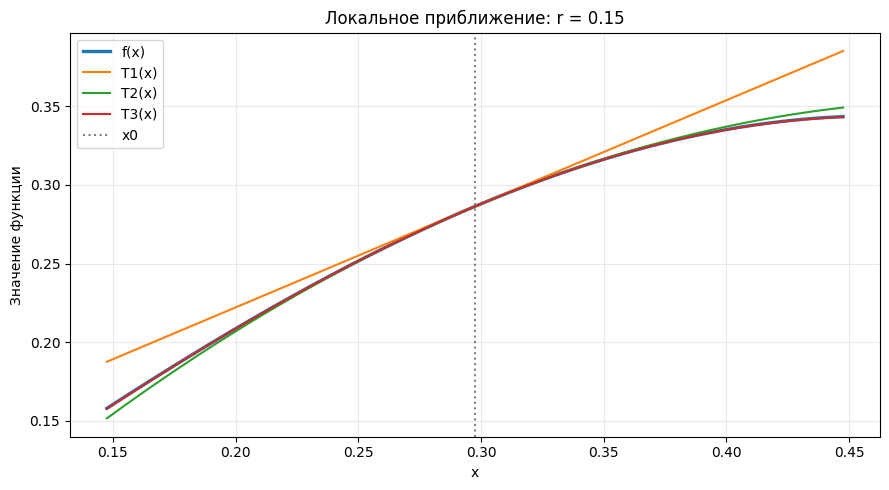

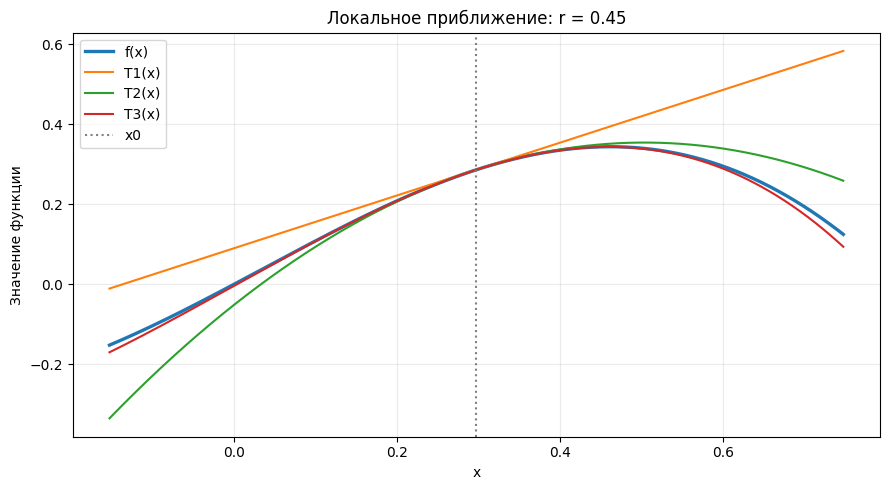

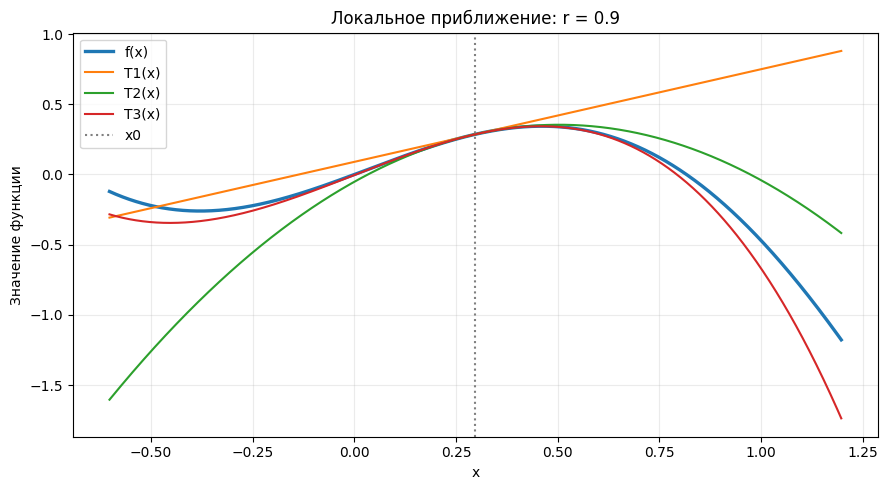

Максимальные наблюдаемые ошибки на сетке:
  Радиус |             T1 |             T2 |             T3
    0.15 |    0.041799382 |    0.006393442 |    0.000336827
    0.45 |    0.458210935 |    0.182921498 |    0.031021949
    0.90 |    2.057739222 |    1.483163826 |    0.559234350


In [15]:
# Графики функции и трёх полиномов для r = 0.15, 0.45, 0.90

radii = [0.15, 0.45, 0.90]
observed_errors = {}

for r in radii:
    xs = np.linspace(x0-r, x0+r, 2001)
    ys = f(xs)
    curves = (T1(xs), T2(xs), T3(xs))
    observed_errors[r] = [float(np.max(np.abs(ys-curve))) for curve in curves]

    plt.figure(figsize=(9, 5))
    plt.plot(xs, ys, label="f(x)", linewidth=2.4)
    for name, curve in zip(("T1(x)", "T2(x)", "T3(x)"), curves):
        plt.plot(xs, curve, label=name)
    plt.axvline(x0, color="gray", linestyle=":", label="x0")
    plt.title(f"Локальное приближение: r = {r}")
    plt.xlabel("x")
    plt.ylabel("Значение функции")
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()

print("Максимальные наблюдаемые ошибки на сетке:")
print(f"{'Радиус':>8} | {'T1':>14} | {'T2':>14} | {'T3':>14}")
for r, values in observed_errors.items():
    print(f"{r:8.2f} | {values[0]:14.9f} | {values[1]:14.9f} | {values[2]:14.9f}")

**Интерпретация графиков.** На меньшей окрестности полиномы ближе к исходной функции. По мере увеличения $r$ максимальные ошибки увеличиваются. На всех трёх выбранных радиусах $T_3$ даёт меньшую наблюдаемую максимальную ошибку, чем $T_1$ и $T_2$.

### 1.3. Теоретическая оценка остатка Лагранжа

Для $T_2$ по формуле Лагранжа

$$
|f(x)-T_2(x)|\leq\frac{M_3(r)}{3!}|x-x_0|^3,
\qquad B_2(r)=\frac{M_3(r)r^3}{6}.
$$

В нашем случае

$$
|f'''(x)|=|ab^3\cos(bx)|\leq|ab^3|=13{,}120609003529.
$$

При $r_L=0{,}45$ отрезок $[x_0-0{,}45,x_0+0{,}45]$ содержит ноль, где $|\cos(2x)|=1$. Поэтому для этого отрезка **точно** $M_3=|ab^3|$.

In [17]:

# Оценка остатка Лагранжа для T2

# Радиус из условия задания
rL = 0.45

# Третья производная:
# f'''(x) = -a*b^3*cos(b*x)
# Так как |cos(b*x)| <= 1,
# можно взять M3 = |a*b^3|
M3 = abs(a * b**3)

# Теоретическая верхняя оценка
B2 = M3 * rL**3 / 6

# Наблюдаемая ошибка на сетке
xs = np.linspace(x0 - rL, x0 + rL, 2001)
delta2 = float(np.max(np.abs(f(xs) - T2(xs))))

print(f"M3 = {M3:.12f}")
print(f"B2 = {B2:.12f}")
print(f"Наблюдаемая ошибка T2 = {delta2:.12f}")

assert delta2 <= B2
print("Наблюдаемая ошибка не превышает оценки Лагранжа")


M3 = 13.120609003529
B2 = 0.199269249241
Наблюдаемая ошибка T2 = 0.182921497956
Наблюдаемая ошибка не превышает оценки Лагранжа


При $r_L=0{,}45$ получаем $B_2\approx0{,}199269249$, тогда как на сетке $\widehat\Delta_2\approx0{,}182921498$. Неравенство $\widehat\Delta_2\leq B_2$ выполняется.

### 1.4. Стационарные точки

Стационарная точка функции удовлетворяет $f'(x)=0$. Для $T_3$ введём $t=x-x_0$. Тогда

$$
T_3'(x)=f'(x_0)+f''(x_0)t+\frac{f'''(x_0)}{2}t^2=0.
$$

Это квадратное уравнение, которое решаем аналитически через дискриминант. Из двух корней выбираем тот, что находится в заданном интервале $[0{,}241636777353;\,0{,}681636777353]$. Корень $f'(x)=0$ на том же интервале находим методом бисекции.

In [19]:
# Аналитически находим стационарную точку T3

stationary_interval = cfg["smooth_function"].get(
    "stationary_interval",
    [0.24163677735302455, 0.6816367773530245]
)
left, right = stationary_interval
A, B, C = d3f(x0)/2, d2f(x0), df(x0)
discriminant = B**2 - 4*A*C
assert discriminant >= 0
roots_t = [(-B + np.sqrt(discriminant))/(2*A),
           (-B - np.sqrt(discriminant))/(2*A)]
roots_x = [x0+t for t in roots_t]
valid = [float(x) for x in roots_x if left <= x <= right]
assert len(valid) == 1, "Ожидался один корень T3' на заданном интервале"
x_T = valid[0]

# Численно находим стационарную точку исходной функции методом бисекции
def bisect_root(fun, left, right, iterations=80):
    a, b = float(left), float(right)
    fa, fb = float(fun(a)), float(fun(b))
    if fa == 0:
        return a
    if fb == 0:
        return b
    if fa*fb > 0:
        raise ValueError("Функция на концах интервала должна иметь разные знаки")
    for _ in range(iterations):
        m = (a+b)/2
        fm = float(fun(m))
        if fa*fm <= 0:
            b = m
        else:
            a, fa = m, fm
    return (a+b)/2

x_star = bisect_root(df, left, right)
print(f"x_T    = {x_T:.12f}")
print(f"x_star = {x_star:.12f}")
print(f"|x_T - x_star| = {abs(x_T-x_star):.12f}")
print(f"|f(x_T) - f(x_star)| = {abs(f(x_T)-f(x_star)):.12f}")

x_T    = 0.459207176772
x_star = 0.461636777353
|x_T - x_star| = 0.002429600581
|f(x_T) - f(x_star)| = 0.000014020583


**Вывод по заданию № 1.** Кубический полином достаточно точно приближает стационарную точку исходной функции: $x_T\approx0{,}459207177$, $x_*\approx0{,}461636777$, а разность их координат составляет около $0{,}00243$. Разность значений исходной функции в этих точках составляет примерно $1{,}402\cdot10^{-5}$. Полином Тейлора является локальной моделью: при удалении от точки разложения точность приближения может заметно ухудшаться.

## Задание 2. Разностные формулы

### 2.1. Вывод через формулу Тейлора

Пусть $f$ достаточно гладкая. Разложим её около точки $x$ с шагом $h>0$:

$$f(x+h)=f(x)+hf'(x)+\frac{h^2}{2}f''(x)+\frac{h^3}{6}f'''(x)+O(h^4),$$
$$f(x-h)=f(x)-hf'(x)+\frac{h^2}{2}f''(x)-\frac{h^3}{6}f'''(x)+O(h^4).$$

**Правая формула.** Из первого разложения выражаем $f'(x)$:

$$f'(x)=\frac{f(x+h)-f(x)}{h}-\frac{h}{2}f''(x)+O(h^2)\;\Rightarrow\; D_+f(x)=\frac{f(x+h)-f(x)}{h}.$$

Погрешность: $D_+f-f'=\frac{h}{2}f''(\xi)=O(h)$ — **первый порядок**.

**Левая формула.** Из второго разложения:

$$f'(x)=\frac{f(x)-f(x-h)}{h}+\frac{h}{2}f''(x)+O(h^2)\;\Rightarrow\; D_-f(x)=\frac{f(x)-f(x-h)}{h}.$$

Погрешность: $D_-f-f'=-\frac{h}{2}f''(\xi)=O(h)$ — тоже **первый порядок**.

**Центральная формула.** Вычитаем второе разложение из первого: члены с $f''$ (чётные степени $h$) сокращаются:

$$f(x+h)-f(x-h)=2hf'(x)+\frac{h^3}{3}f'''(x)+O(h^5)$$
$$\Rightarrow\; D_0f(x)=\frac{f(x+h)-f(x-h)}{2h},\qquad D_0f-f'=\frac{h^2}{6}f'''(\xi)=O(h^2).$$

### 2.2. Порядок погрешности

- У односторонних формул главный член ошибки $\pm\frac{h}{2}f''(x)$ пропорционален $h$: уменьшение шага в 10 раз уменьшает ошибку примерно в 10 раз. На log–log графике это прямая с наклоном **+1**.
- У центральной формулы $f''$ сокращается благодаря симметрии, остаётся $\frac{h^2}{6}f'''(x)$: шаг в 10 раз меньше — ошибка в 100 раз меньше. Наклон **+2**.
- Заметим, что $D_0=\frac{D_++D_-}{2}$: усреднение двух ошибок $\pm\frac{h}{2}f''$ убирает главный член.

### 2.3. Условия гладкости

- Для $D_\pm$ с оценкой $O(h)$ достаточно $f\in C^2$ на $[x-h,x+h]$ (или хотя бы $f'$ непрерывна и $f''$ ограничена — тогда остаток в форме Лагранжа $\frac{h}{2}f''(\xi)$ корректен).
- Для $D_0$ с оценкой $O(h^2)$ нужно $f\in C^3$ (достаточно ограниченной $f'''$) на $[x-h,x+h]$.
- Константа в оценке содержит $M_2=\max|f''|$ и $M_3=\max|f'''|$: чем резче меняется функция, тем больше ошибка.
- Если гладкости не хватает, порядок падает. Проверим это на $f(x)=x|x|$ в $x_0=0$: здесь $f'(0)=0$, но $f''$ имеет разрыв ($f'' = 2\,\mathrm{sign}\,x$), $f'''$ не существует. Центральная формула даёт $D_0=h$, то есть порядок $O(h)$, а не $O(h^2)$.
- Формулы выведены для точной арифметики; на компьютере к ним добавляется ошибка округления (задание 3).
### 2.4. Что означают O(h) и O(h²) в этой задаче (своими словами)
Запись $e(h)=O(h)$ значит: при малом $h$ ошибка не больше $C\,h$, где $C\approx|f''(x_0)|/2$ — число, не зависящее от шага. Уменьшили шаг в 10 раз — ошибка упала примерно в 10 раз. $e(h)=O(h^2)$ значит $e\le C\,h^2$ с $C\approx|f'''(x_0)|/6$: шаг меньше в 10 раз — ошибка меньше примерно в 100 раз. Для нашей функции в $x_0$ это можно проверить числами: на шаге $0{,}1$ ошибка правой разности $\approx0{,}18$, центральной $\approx0{,}018$ (блок 3.6), на шаге $10^{-5}$ — $1{,}6\cdot10^{-5}$ и $1{,}8\cdot10^{-10}$.

In [ ]:
# Блок 2.1: проверка условия гладкости на f(x) = x*|x| в точке 0
g = lambda x: x * np.abs(x)
hs = 10.0 ** np.arange(-1, -8, -1)
x_n = cfg["nonsmooth_test"]["x0"]          # = 0, точная производная g'(0) = 0
err_c = np.abs((g(x_n + hs) - g(x_n - hs)) / (2 * hs) - 0.0)

print(pd.DataFrame({"h": hs, "|D0 - g'(0)|": err_c, "ошибка / h": err_c / hs}).to_string(index=False))
slope = np.polyfit(np.log10(hs), np.log10(err_c), 1)[0]
print(f"Наклон в log-log: {slope:.2f}  (для гладкой f было бы 2, здесь 1)")

## Задание 3. Погрешность и машинная арифметика

План: считаем $D_+,D_-,D_0$ в точке $x_0$ на сетке шагов $h\in[10^{-20},1]$ (260 точек, логарифмическая сетка) в `float64` и `float32`, сравниваем с аналитическим $f'(x_0)$.

In [ ]:
# Блок 3.1: три разностные формулы
def forward(func, x, h):  return (func(x + h) - func(x)) / h
def backward(func, x, h): return (func(x) - func(x - h)) / h
def central(func, x, h):  return (func(x + h) - func(x - h)) / (2 * h)

METHODS = {"правая D+": forward, "левая D-": backward, "центральная D0": central}

In [ ]:
# Блок 3.2: эксперимент для float64 и float32
h_grid = np.logspace(np.log10(exp["h_min"]), np.log10(exp["h_max"]), exp["n_h"])

def run(dtype):
    """Считает |D - f'(x0)| для всех методов, вычисления идут в заданном типе dtype."""
    x = dtype(x0)
    h = h_grid.astype(dtype)
    fd = lambda t: (dtype(a) * np.sin(dtype(b) * t) + dtype(c) * t * t + dtype(d) * t).astype(dtype)
    res = {}
    with np.errstate(all="ignore"):
        for name, m in METHODS.items():
            res[name] = np.abs(m(fd, x, h).astype(np.float64) - exact)
    return res

err64 = run(np.float64)
err32 = run(np.float32)
print("Готово: шагов", len(h_grid), "| float64 и float32")

In [ ]:
# Блок 3.3: графики ошибок в log-log (по одному на тип данных) + опорные наклоны
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (title, err) in zip(axes, [("float64", err64), ("float32", err32)]):
    for name, e in err.items():
        ax.loglog(h_grid, np.where(e > 0, e, np.nan), label=name)
    # опорные прямые O(h) и O(h^2)
    ax.loglog(h_grid, 1e0 * h_grid, "k--", lw=0.8, label="~ h")
    ax.loglog(h_grid, 1e0 * h_grid**2, "k:", lw=0.8, label="~ h²")
    ax.set_title(f"Ошибка производной, {title}")
    ax.set_xlabel("h"); ax.set_ylim(1e-17, 1e2); ax.legend()
axes[0].set_ylabel("|D - f'(x0)|")
plt.tight_layout(); plt.show()

In [ ]:
# Блок 3.3a: пункт 1 - e+(h), e-(h), e0(h) на ОДНОМ log-log графике (float64)
plt.figure(figsize=(9, 6))
for name, e in err64.items():
    plt.loglog(h_grid, np.where(e > 0, e, np.nan), label=name)
plt.loglog(h_grid, h_grid, "k--", lw=0.8, label="наклон 1")
plt.loglog(h_grid, h_grid**2, "k:", lw=0.8, label="наклон 2")
plt.xlabel("h"); plt.ylabel("|D - f'(x0)|"); plt.ylim(1e-17, 1e2)
plt.title("Ошибки трёх разностных формул, float64"); plt.legend(); plt.show()

In [ ]:
# Блок 3.3b: пункт 2 - наклон на "прямом" участке (там, где округление ещё не мешает)
def fit_slope(err, lo, hi):
    """Наклон p в log e = log C + p log h на участке h in [lo, hi] (МНК)."""
    m = (h_grid >= lo) & (h_grid <= hi) & (err > 0)
    p, logC = np.polyfit(np.log10(h_grid[m]), np.log10(err[m]), 1)
    return p, 10 ** logC

ranges = {"правая D+": (1e-4, 1e-2), "левая D-": (1e-4, 1e-2), "центральная D0": (1e-2, 1e-1)}
theory = {"правая D+": 1, "левая D-": 1, "центральная D0": 2}
rows = []
for name, (lo, hi) in ranges.items():
    p, Cc = fit_slope(err64[name], lo, hi)
    rows.append({"формула": name, "участок h": f"{lo:g} ... {hi:g}", "наклон p": p, "теория": theory[name], "C": Cc})
print(pd.DataFrame(rows).to_string(index=False))
print(f"Оценки C из теории: |f2|/2 = {abs(d2f(x0))/2:.3f},  |f3|/6 = {abs(d3f(x0))/6:.3f}")

In [ ]:
# Блок 3.4: сравнение float32 и float64 на одном графике (центральная формула и правая)
plt.figure(figsize=(9, 5))
for name, st in [("центральная D0", "-"), ("правая D+", "--")]:
    plt.loglog(h_grid, np.where(err64[name] > 0, err64[name], np.nan), "C0" + st, label=f"{name}, float64")
    plt.loglog(h_grid, np.where(err32[name] > 0, err32[name], np.nan), "C3" + st, label=f"{name}, float32")
plt.xlabel("h"); plt.ylabel("ошибка"); plt.ylim(1e-17, 1e2)
plt.title("float32 против float64"); plt.legend(); plt.show()

In [ ]:
# Блок 3.5: шаги с минимальной наблюдаемой ошибкой + теоретическая оценка
M2 = np.max(np.abs(d2f(np.linspace(x0 - 1, x0 + 1, 2001))))
M3 = np.max(np.abs(d3f(np.linspace(x0 - 1, x0 + 1, 2001))))
f_scale = max(abs(f(x0)), 1.0)

rows = []
for tname, err, eps in [("float64", err64, np.finfo(np.float64).eps), ("float32", err32, np.finfo(np.float32).eps)]:
    for name, e in err.items():
        i = np.nanargmin(e)
        if "D0" in name:
            h_th = (3 * eps * f_scale / M3) ** (1 / 3)
        else:
            h_th = 2 * np.sqrt(eps * f_scale / M2)
        rows.append({"тип": tname, "формула": name, "h_min_obs": h_grid[i],
                     "min ошибка": e[i], "h_opt теория": h_th})
table = pd.DataFrame(rows)
print(table.to_string(index=False))

In [ ]:
# Блок 3.5a: сравнение положения минимумов с масштабами (15): h± ~ eps^(1/2), h0 ~ eps^(1/3)
rows = []
for tname, err, eps in [("float64", err64, np.finfo(np.float64).eps), ("float32", err32, np.finfo(np.float32).eps)]:
    for name, e in err.items():
        h_obs = h_grid[np.nanargmin(e)]
        scale = eps ** (1 / 3) if "D0" in name else eps ** 0.5
        rows.append({"тип": tname, "формула": name, "h_min наблюд.": h_obs,
                     "масштаб eps^(1/p)": scale, "отношение": h_obs / scale})
print(pd.DataFrame(rows).to_string(index=False))
print("Отношение порядка 1 (в пределах 1-2 порядков) = масштаб (15) подтверждается.")

In [ ]:
# Блок 3.6: ошибки на контрольных шагах из задания (0.1, 1e-5, 1e-17)
rows = []
for label, hv in steps.items():
    for tname, dt in [("float64", np.float64), ("float32", np.float32)]:
        x = dt(x0); h = dt(hv)
        fd = lambda t: (dt(a) * np.sin(dt(b) * t) + dt(c) * t * t + dt(d) * t).astype(dt)
        for name, m in METHODS.items():
            val = float(m(fd, x, h))
            rows.append({"шаг": f"{label} ({hv:g})", "тип": tname, "формула": name, "значение": val,
                         "|ошибка|": abs(val - exact)})
print("Точное f'(x0) =", exact)
print(pd.DataFrame(rows).to_string(index=False))

In [ ]:
# Блок 3.7: что происходит при слишком малом h - x0 + h == x0
for dt in (np.float64, np.float32):
    eps = np.finfo(dt).eps
    x = dt(x0)
    print(f"{dt.__name__}: eps = {eps:.3e}, eps*|x0|/2 = {eps*abs(x0)/2:.3e}")
    for hv in (1e-5, 1e-8, 1e-10, 1e-17):
        h = dt(hv)
        print(f"   h = {hv:7.0e}:  x0+h == x0 ? {bool(x + h == x)},  f(x0+h)-f(x0) = {float(f(x+h, np) - f(x, np)):.3e}")

In [ ]:
# Блок 3.8: пункт 4 - 0.1 + 0.2 == 0.3 и eps через nextafter
print("0.1 + 0.2 == 0.3 ?", 0.1 + 0.2 == 0.3)
print("0.1 + 0.2 =", repr(0.1 + 0.2), "| 0.3 =", repr(0.3), "| разность =", (0.1 + 0.2) - 0.3)
print("float32:", np.float32(0.1) + np.float32(0.2) == np.float32(0.3))

for dt in (np.float32, np.float64):
    one = dt(1.0)
    gap = np.nextafter(one, dt(2.0)) - one
    print(f"{dt.__name__}: eps = {np.finfo(dt).eps:.6e},  nextafter(1) - 1 = {float(gap):.6e},  совпадают: {float(gap) == float(np.finfo(dt).eps)}")
print("1.0 + 1e-16 == 1.0 (float64):", 1.0 + 1e-16 == 1.0)

**Пояснение к блоку 3.8.** Числа 0.1, 0.2, 0.3 не представимы точно в двоичной системе (как $1/3$ в десятичной), в памяти хранятся ближайшие двоичные дроби. Сумма двух округлённых чисел округляется ещё раз и оказывается на один шаг сетки от округлённого 0.3, поэтому `0.1 + 0.2 == 0.3` даёт `False`. `eps` — это ровно расстояние от 1 до следующего представимого числа (`nextafter`), т.е. относительный шаг сетки чисел около 1: $2^{-23}$ для float32 и $2^{-52}$ для float64. Любая добавка меньше примерно половины этого шага не меняет число.

### Анализ результатов

*(Числа — в таблицах блоков 3.5–3.6; ниже — выводы, которые видны на графиках.)*

1. **Правая и левая формулы** на правой части графика (большие $h$) дают прямую с наклоном $+1$, т.е. $O(h)$. **Центральная** — наклон $+2$, $O(h^2)$: при одинаковом $h$ она точнее на много порядков.
2. **У графика форма «V»/«галочки»**. Слева от минимума ошибка растёт при уменьшении $h$ — это ошибка округления. Суммарная ошибка оценивается как
$$E(h)\approx \underbrace{C\,h^{p}}_{\text{метода}}+\underbrace{\frac{\varepsilon\,|f|}{h}}_{\text{округления}},$$
где $p=1$ или $2$, $\varepsilon$ — машинная точность. Числитель $f(x+h)-f(x)$ — разность почти равных чисел (катастрофическая потеря точности), и её абсолютная ошибка порядка $\varepsilon|f|$ делится на малое $h$.
3. **Оптимальный шаг**: для $D_\pm$ порядка $\sqrt\varepsilon$ ($\approx10^{-8}$ в float64, $\approx10^{-4}$ в float32), для $D_0$ порядка $\sqrt[3]{\varepsilon}$ ($\approx10^{-5}$ в float64, $\approx10^{-2}$ в float32). Наблюдаемые минимумы (блок 3.5) совпадают с теорией по порядку величины. Минимальная ошибка у $D_0$ заметно меньше ($\sim\varepsilon^{2/3}$ против $\sim\varepsilon^{1/2}$).
4. **float32 против float64**: у float32 $\varepsilon\approx1.2\cdot10^{-7}$ против $2.2\cdot10^{-16}$, поэтому минимум ошибки на 5–6 порядков хуже (для D0: ≈2·10⁻⁶ против ≈6·10⁻¹²), а оптимальный шаг больше. Участок «чистой» методической ошибки у float32 короче.
5. **Слишком малый шаг** ($h=10^{-17}$ и меньше): $h$ меньше $\varepsilon|x_0|/2$, поэтому `x0 + h == x0`, значения $f(x_0+h)$ и $f(x_0)$ совпадают, разность равна 0 и производная получается $0$. Ошибка становится равной $|f'(x_0)|$ (горизонтальная «полка» на графике). Для float32 это происходит уже при $h\sim10^{-8}$.
6. **Практический вывод**: «меньше шаг — точнее» неверно. Брать $h\approx\sqrt\varepsilon$ для $D_\pm$ и $h\approx\sqrt[3]\varepsilon$ для $D_0$; для контрольного шага $10^{-5}$ центральная формула в float64 близка к пределу точности, а $10^{-17}$ даёт полностью неверный результат.

## 4. Недостаточная гладкость

### 4.1. Аналитический вывод

Рассмотрим

$$
g(x)=x|x|=\begin{cases}x^2,&x\geq0,\\-x^2,&x<0.\end{cases}
$$

В нуле $g(0)=0$, поэтому по определению производной

$$
g'(0)=\lim_{h\to0}\frac{g(h)-g(0)}{h}=\lim_{h\to0}|h|=0.
$$

При $h>0$ центральная разность равна

$$
D_h^0g(0)=\frac{g(h)-g(-h)}{2h}=\frac{h^2-(-h^2)}{2h}=h.
$$

Следовательно, точная ошибка

$$
e_g(h)=|D_h^0g(0)-g'(0)|=h=O(h).
$$

Порядок равен **1**, а не **2**. При $x>0$ имеем $g'(x)=2x$, при $x<0$ — $g'(x)=-2x$. Таким образом, в точке $0$ вторая производная не существует, и обычные условия второго порядка точности центральной разности не выполнены.

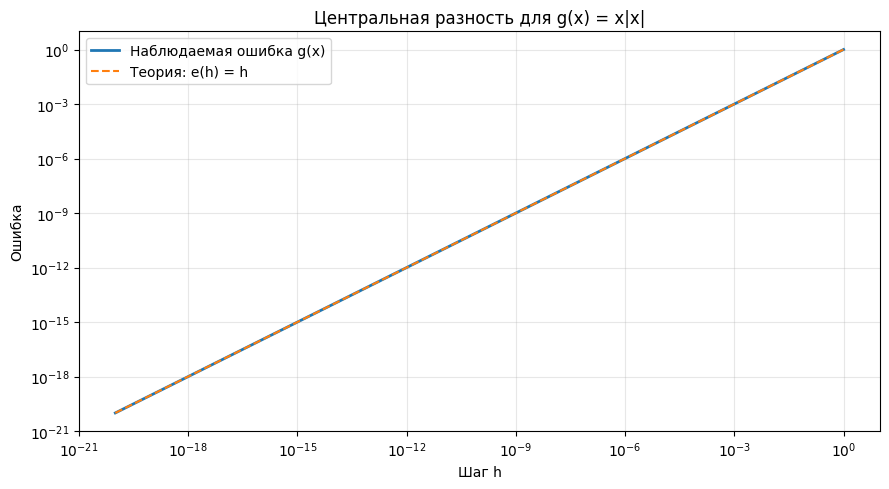

Оценочный наклон log-log: 1.00000000


In [24]:
# Проверяем e_g(h) = h на 260 шагах, затем оцениваем наклон log-log

def g(x):
    return x * np.abs(x)

h_grid = np.logspace(
    np.log10(exp["h_min"]),
    np.log10(exp["h_max"]),
    int(exp["n_h"]),
)

g_prime_0 = 0.0
D0_g = (g(h_grid) - g(-h_grid)) / (2 * h_grid)
errors_g = np.abs(D0_g - g_prime_0)

mask = (h_grid >= 1e-8) & (h_grid <= 1e-2) & (errors_g > 0)
slope = np.polyfit(np.log10(h_grid[mask]), np.log10(errors_g[mask]), 1)[0]

plt.figure(figsize=(9, 5))
plt.loglog(h_grid, errors_g, label="Наблюдаемая ошибка g(x)", linewidth=2)
plt.loglog(h_grid, h_grid, "--", label="Теория: e(h) = h")
plt.xlabel("Шаг h")
plt.ylabel("Ошибка")
plt.title("Центральная разность для g(x) = x|x|")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Оценочный наклон log-log: {slope:.8f}")
assert np.isclose(slope, 1.0, atol=1e-3)

### 4.2. Сравнение с функцией $|x|$

Для $q(x)=|x|$ в точке $0$ правая производная равна $1$, а левая $-1$:

$$
q'_+(0)=1,\qquad q'_-(0)=-1.
$$

Следовательно, обычная производная $q'(0)$ не существует. Однако центральная разность возвращает

$$
D_h^0q(0)=\frac{|h|-|-h|}{2h}=0.
$$

Численная формула может вернуть число, даже если сама производная не существует. Поэтому говорить об ошибке $|D_h^0q(0)-q'(0)|$ в этой точке некорректно.

In [25]:
def q(x):
    return np.abs(x)

h = 1e-3
central_abs = (q(h)-q(-h))/(2*h)
right_abs = (q(h)-q(0))/h
left_abs = (q(0)-q(-h))/h
print("Для |x| в точке 0:")
print("Центральная разность:", central_abs)
print("Правая разность:", right_abs)
print("Левая разность:", left_abs)
assert central_abs == 0 and right_abs == 1 and left_abs == -1

Для |x| в точке 0:
Центральная разность: 0.0
Правая разность: 1.0
Левая разность: -1.0


**Вывод по заданию № 4.** Для $g(x)=x|x|$ наблюдаемый наклон на log–log графике близок к $1$, что согласуется с точной зависимостью $e_g(h)=h$. Недостаточная гладкость может снижать порядок точности численного дифференцирования. Пример $|x|$ показывает, что вычисленное число не доказывает существования производной.